# Análisis Exploratorio de Señales IMU (EuRoC MAV)
Este notebook carga, grafica y extrae estadísticas de las señales inerciales y de posición de las secuencias del dataset EuRoC, respetando la estructura de directorios previamente definida (`data/raw/...`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Configuración visual de los gráficos
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 5)

## 1. Carga de Datos
Asumimos que el código se ejecuta desde la raíz del proyecto. Cambia `V1_01_easy` por las otras secuencias para analizarlas individualmente.

In [7]:
# Definir rutas
##__file__ is not defined
# PARENT_DIR = Path(__file__).resolve().parent.parent
PARENT_DIR = Path.cwd().parent
BASE_DIR = PARENT_DIR / 'data/raw/V1_01_easy'
IMU_PATH = BASE_DIR / 'imu0' / 'data.csv'
GT_PATH = BASE_DIR / 'state_groundtruth_estimate0' / 'data.csv'

# Leer CSVs
df_imu = pd.read_csv(IMU_PATH)
df_gt = pd.read_csv(GT_PATH)

print(f"Dimensiones IMU: {df_imu.shape}")
print(f"Dimensiones Ground Truth: {df_gt.shape}")
print("\nPrimeras columnas de la IMU:", df_imu.columns.tolist()[:7])

Dimensiones IMU: (29120, 7)
Dimensiones Ground Truth: (28712, 17)

Primeras columnas de la IMU: ['#timestamp [ns]', 'w_RS_S_x [rad s^-1]', 'w_RS_S_y [rad s^-1]', 'w_RS_S_z [rad s^-1]', 'a_RS_S_x [m s^-2]', 'a_RS_S_y [m s^-2]', 'a_RS_S_z [m s^-2]']


## 2. Alineamiento de Tiempos
El timestamp original está en nanosegundos absolutos. Los normalizamos a segundos relativos desde el inicio de la captura.

In [8]:
ts_col_imu = df_imu.columns[0]
ts_col_gt = df_gt.columns[0]

df_imu['time_sec'] = (df_imu[ts_col_imu] - df_imu[ts_col_imu].iloc[0]) / 1e9
df_gt['time_sec'] = (df_gt[ts_col_gt] - df_gt[ts_col_gt].iloc[0]) / 1e9

# Verificar la frecuencia teórica de EuRoC (aprox. 200 Hz para el IMU)
dt_mean = np.mean(np.diff(df_imu['time_sec']))
print(f"Frecuencia de muestreo estimada (IMU): {1 / dt_mean :.2f} Hz")

Frecuencia de muestreo estimada (IMU): 200.00 Hz


## 3. Visualización de Aceleración y Giroscopio
Identificamos el comportamiento y el ruido base del sensor para considerarlo en el modelado RNN/LSTM.

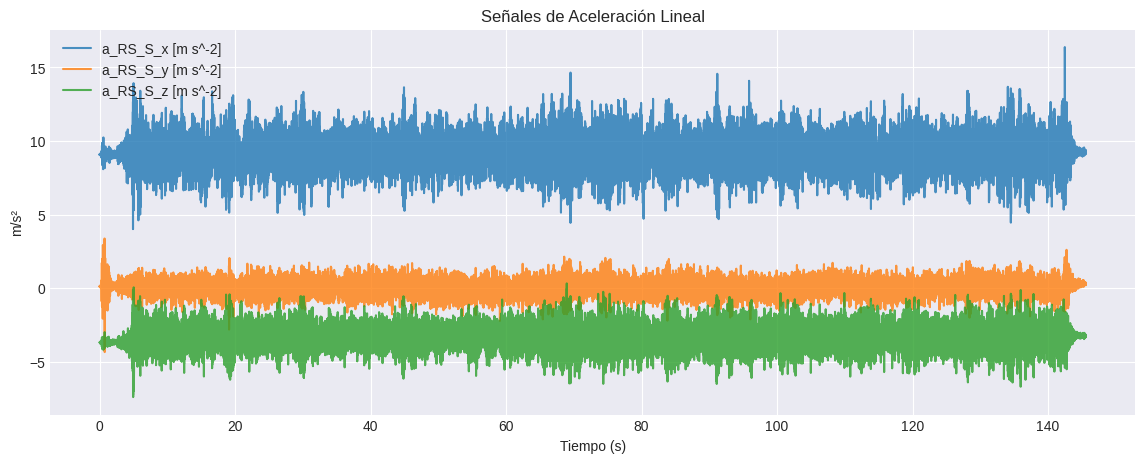

In [9]:
# Aceleración (Típicamente columnas 4, 5, 6: a_RS_S_x, a_RS_S_y, a_RS_S_z)
acc_cols = df_imu.columns[4:7]

plt.figure()
for col in acc_cols:
    plt.plot(df_imu['time_sec'], df_imu[col], label=col, alpha=0.8)
plt.title('Señales de Aceleración Lineal')
plt.xlabel('Tiempo (s)')
plt.ylabel('m/s²')
plt.legend()
plt.show()

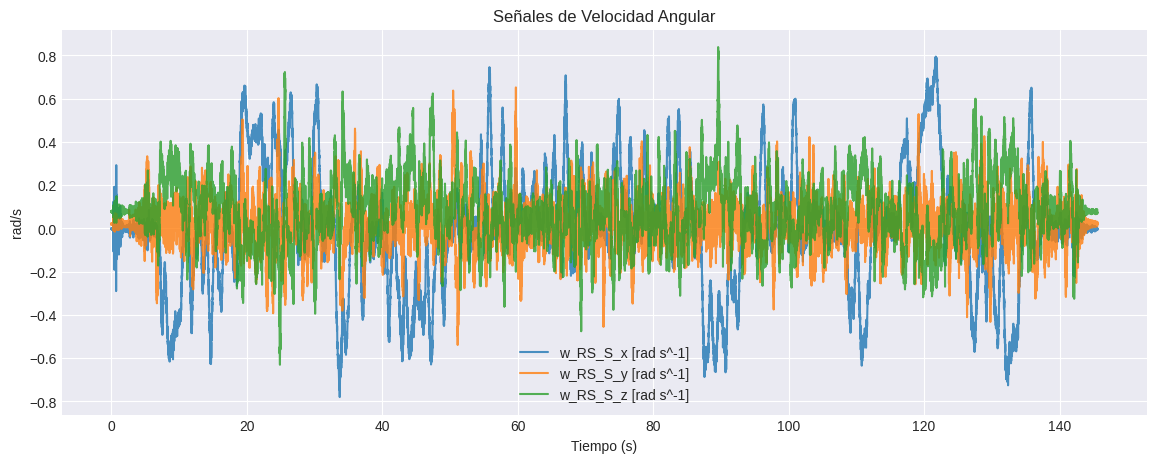

In [10]:
# Giroscopio (Típicamente columnas 1, 2, 3: w_RS_S_x, w_RS_S_y, w_RS_S_z)
gyro_cols = df_imu.columns[1:4]

plt.figure()
for col in gyro_cols:
    plt.plot(df_imu['time_sec'], df_imu[col], label=col, alpha=0.8)
plt.title('Señales de Velocidad Angular')
plt.xlabel('Tiempo (s)')
plt.ylabel('rad/s')
plt.legend()
plt.show()

## 4. Extracción de Estadísticas (Vital para Forecasting)
Las redes neuronales necesitan datos estandarizados. Extraemos la media y desviación estándar global para implementarlas en `src/data_pipeline.py`.

In [11]:
features = list(gyro_cols) + list(acc_cols)
stats = df_imu[features].describe().T
stats['rango'] = stats['max'] - stats['min']

print("Estadísticas del dataset IMU para inicializar Normalizadores (Z-Score / Min-Max):\n")
display(stats)

# Verificamos ausencia de nulos
print(f"\nTotal de valores nulos (NaN): {df_imu[features].isna().sum().sum()}")

Estadísticas del dataset IMU para inicializar Normalizadores (Z-Score / Min-Max):



,count,mean,std,min,25%,50%,75%,max,rango
w_RS_S_x [rad s^-1],29120.0,-0.006702,0.266905,-0.780511,-0.106814,-0.002793,0.097913,0.793776,1.574287
w_RS_S_y [rad s^-1],29120.0,0.021822,0.113404,-0.539656,-0.039794,0.020944,0.082380,0.651357,1.191013
w_RS_S_z [rad s^-1],29120.0,0.078641,0.150928,-0.631111,-0.013963,0.076096,0.168948,0.837758,1.468869
a_RS_S_x [m s^-2],29120.0,9.191204,1.138703,4.012554,8.450063,9.193734,9.929233,16.377105,12.364551
a_RS_S_y [m s^-2],29120.0,0.023886,0.519805,-4.339443,-0.310544,0.032689,0.359577,3.375122,7.714565
a_RS_S_z [m s^-2],29120.0,-3.305667,0.849933,-7.395849,-3.865455,-3.317917,-2.737690,0.326888,7.722737



Total de valores nulos (NaN): 0


## 5. Visualización de Ground Truth
Observar la posición base ayudará a correlacionar visualmente los cambios bruscos de la IMU con los movimientos reales del dron.

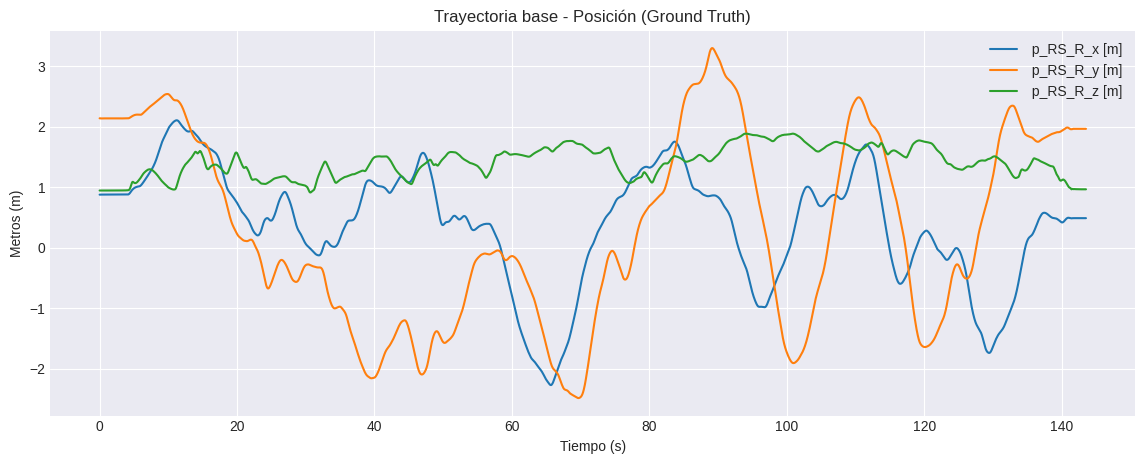

In [12]:
# Posición (Típicamente columnas 1, 2, 3: p_RS_R_x, p_RS_R_y, p_RS_R_z)
pos_cols = df_gt.columns[1:4]

plt.figure()
for col in pos_cols:
    plt.plot(df_gt['time_sec'], df_gt[col], label=col)
plt.title('Trayectoria base - Posición (Ground Truth)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Metros (m)')
plt.legend()
plt.show()